Persiapan Data (Data Preparation)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Membaca dataset
file_path = "Data Pendukung BPHTB PAK 2026 dan Target 2027.xlsx"
df = pd.read_excel(file_path, sheet_name="uraian", header=None)

# Kolom realisasi BPHTB setiap tahun
kolom_realisasi = {
    2021: 4,
    2022: 8,
    2023: 12,
    2024: 16,
    2025: 24,
    2026: 32
}

# Menyusun data realisasi bulanan
data = []

for tahun, kolom in kolom_realisasi.items():
    jumlah_bulan = 8 if tahun == 2026 else 12

    for bulan in range(1, jumlah_bulan + 1):
        nilai = df.iloc[bulan + 4, kolom]

        data.append({
            "Tanggal": pd.Timestamp(tahun, bulan, 1),
            "Realisasi_BPHTB": float(nilai)
        })

# Membentuk dataframe deret waktu
bphtb = pd.DataFrame(data)
bphtb = bphtb.set_index("Tanggal").sort_index()

# Memeriksa hasil
print("Jumlah pengamatan:", len(bphtb))
print("\n5 Data Awal:")
display(bphtb.head())

print("\n5 Data Akhir:")
display(bphtb.tail())

Jumlah pengamatan: 68

5 Data Awal:


,Realisasi_BPHTB
Tanggal,
2021-01-01,2.244094e+10
2021-02-01,7.558455e+10
2021-03-01,8.981147e+10
2021-04-01,1.027601e+11
2021-05-01,7.878186e+10



5 Data Akhir:


,Realisasi_BPHTB
Tanggal,
2026-04-01,7.888727e+10
2026-05-01,7.354266e+10
2026-06-01,1.109578e+11
2026-07-01,2.454398e+11
2026-08-01,1.015473e+11


Pemeriksaan Kualitas Data (Data Quality Check)

In [2]:
# Pemeriksaan kualitas data BPHTB

print("Jumlah pengamatan:", len(bphtb))
print("Jumlah nilai kosong:", bphtb["Realisasi_BPHTB"].isna().sum())
print("Jumlah tanggal duplikat:", bphtb.index.duplicated().sum())
print("Jumlah nilai nol:", (bphtb["Realisasi_BPHTB"] == 0).sum())
print("Jumlah nilai negatif:", (bphtb["Realisasi_BPHTB"] < 0).sum())

# Memeriksa kelengkapan periode bulanan
periode_lengkap = pd.date_range(
    start=bphtb.index.min(),
    end=bphtb.index.max(),
    freq="MS"
)

periode_hilang = periode_lengkap.difference(bphtb.index)

print("Jumlah periode yang hilang:", len(periode_hilang))
print("Periode yang hilang:", list(periode_hilang))

Jumlah pengamatan: 68
Jumlah nilai kosong: 0
Jumlah tanggal duplikat: 0
Jumlah nilai nol: 0
Jumlah nilai negatif: 0
Jumlah periode yang hilang: 0
Periode yang hilang: []


Pembagian Data Latih dan Data Uji (Train-Test Split)

In [3]:
# Membagi data berdasarkan urutan waktu

train = bphtb.loc["2021-01":"2024-12"].copy()
test = bphtb.loc["2025-01":"2025-12"].copy()
data_tambahan = bphtb.loc["2026-01":"2026-08"].copy()

# Menampilkan hasil pembagian
print("Jumlah data latih:", len(train))
print("Jumlah data uji:", len(test))
print("Jumlah data tambahan:", len(data_tambahan))

print("\nPeriode Data Latih:")
print(train.index.min(), "sampai", train.index.max())

print("\nPeriode Data Uji:")
print(test.index.min(), "sampai", test.index.max())

print("\nPeriode Data Tambahan:")
print(data_tambahan.index.min(), "sampai", data_tambahan.index.max())

Jumlah data latih: 48
Jumlah data uji: 12
Jumlah data tambahan: 8

Periode Data Latih:
2021-01-01 00:00:00 sampai 2024-12-01 00:00:00

Periode Data Uji:
2025-01-01 00:00:00 sampai 2025-12-01 00:00:00

Periode Data Tambahan:
2026-01-01 00:00:00 sampai 2026-08-01 00:00:00


Analisis Rolling Mean dan Rolling Standard Deviation

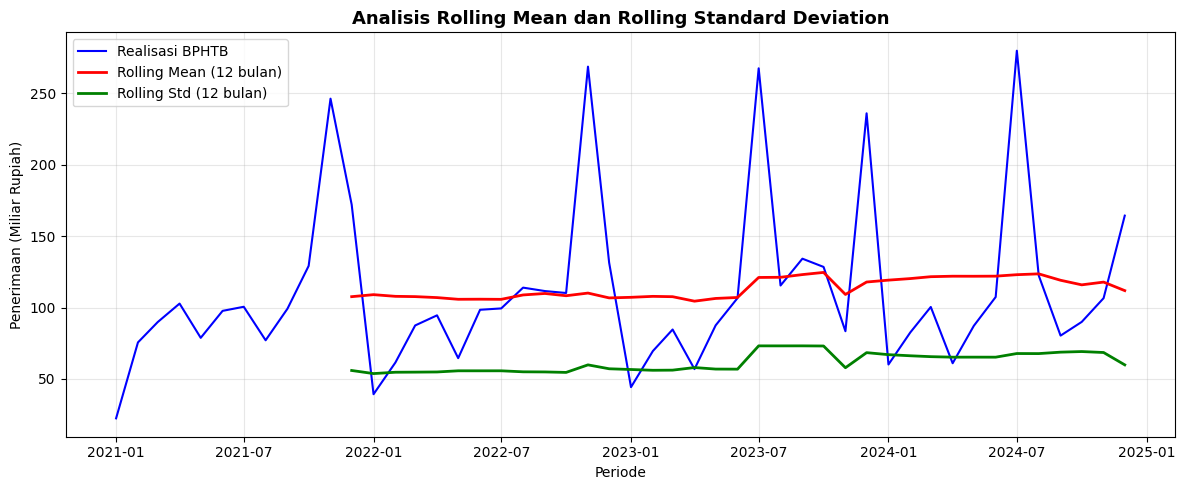

In [4]:
# Analisis rolling statistics pada data latih

import matplotlib.pyplot as plt

# Mengubah satuan menjadi miliar rupiah
y_train = train["Realisasi_BPHTB"] / 1e9

# Rolling window 12 bulan
rolling_mean = y_train.rolling(window=12).mean()
rolling_std = y_train.rolling(window=12).std()

# Visualisasi
plt.figure(figsize=(12, 5))

plt.plot(
    y_train,
    label="Realisasi BPHTB",
    color="blue",
    linewidth=1.5
)

plt.plot(
    rolling_mean,
    label="Rolling Mean (12 bulan)",
    color="red",
    linewidth=2
)

plt.plot(
    rolling_std,
    label="Rolling Std (12 bulan)",
    color="green",
    linewidth=2
)

plt.title(
    "Analisis Rolling Mean dan Rolling Standard Deviation",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Periode")
plt.ylabel("Penerimaan (Miliar Rupiah)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Uji Stasioneritas ADF

In [17]:
from statsmodels.tsa.stattools import adfuller

# Menggunakan data latih dalam satuan miliar rupiah
y_train = train["Realisasi_BPHTB"] / 1e9

# Melakukan uji ADF
hasil_adf = adfuller(y_train, autolag="AIC")

print("HASIL UJI ADF")
print(f"ADF Statistic : {hasil_adf[0]:.6f}")
print(f"P-value       : {hasil_adf[1]:.6f}")
print(f"Jumlah Lag    : {hasil_adf[2]}")
print(f"Observasi     : {hasil_adf[3]}")

print("\nCritical Values:")
for key, value in hasil_adf[4].items():
    print(f"{key}: {value:.6f}")

print("\nKesimpulan:")
if hasil_adf[1] < 0.05:
    print("H0 ditolak: Data stasioner menurut uji ADF.")
else:
    print("H0 gagal ditolak: Belum cukup bukti bahwa data stasioner.")

HASIL UJI ADF
ADF Statistic : -4.647642
P-value       : 0.000105
Jumlah Lag    : 5
Observasi     : 42

Critical Values:
1%: -3.596636
5%: -2.933297
10%: -2.604991

Kesimpulan:
H0 ditolak: Data stasioner menurut uji ADF.


/tmp/ipykernel_2156/3146851484.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil_adf = adfuller(y_train, autolag="AIC")


Analisis Autocorrelation Function (ACF)

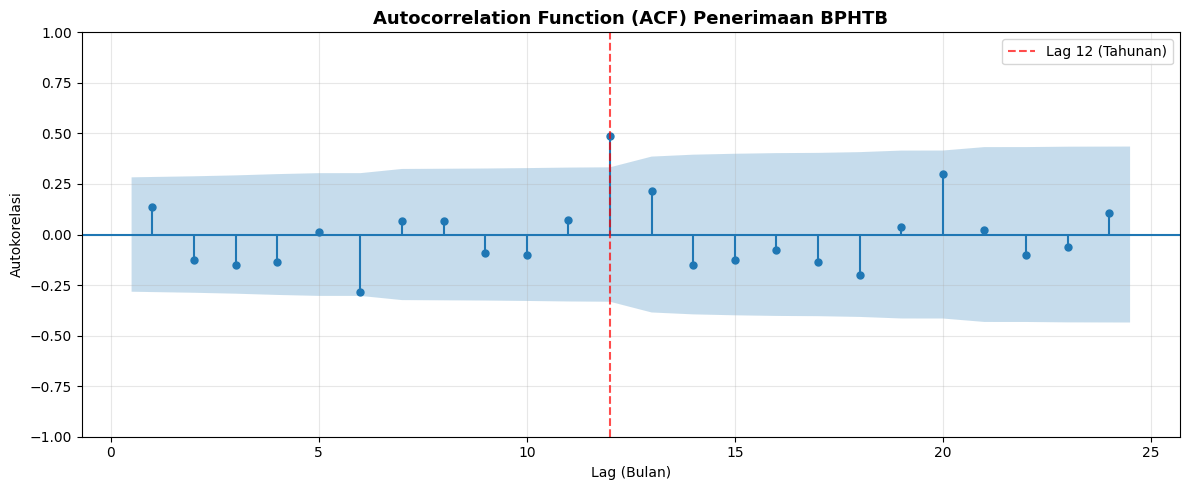

In [6]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

# Menggunakan data latih
y_train = train["Realisasi_BPHTB"] / 1e9

# Membuat grafik ACF
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    y_train,
    lags=24,
    alpha=0.05,
    zero=False,
    ax=ax
)

ax.set_title(
    "Autocorrelation Function (ACF) Penerimaan BPHTB",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Lag (Bulan)")
ax.set_ylabel("Autokorelasi")

ax.axvline(
    x=12,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Lag 12 (Tahunan)"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Analisis Partial Autocorrelation Function (PACF)

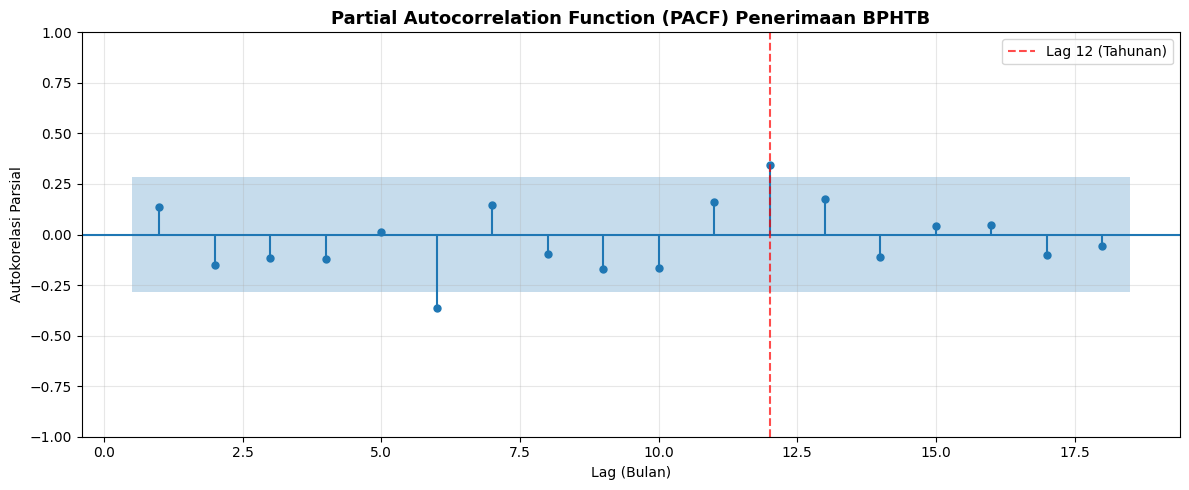

In [7]:
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

# Menggunakan data latih
y_train = train["Realisasi_BPHTB"] / 1e9

# Membuat grafik PACF
fig, ax = plt.subplots(figsize=(12, 5))

plot_pacf(
    y_train,
    lags=18,
    alpha=0.05,
    method="ywm",
    zero=False,
    ax=ax
)

ax.set_title(
    "Partial Autocorrelation Function (PACF) Penerimaan BPHTB",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Lag (Bulan)")
ax.set_ylabel("Autokorelasi Parsial")

# Penanda lag musiman tahunan
ax.axvline(
    x=12,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Lag 12 (Tahunan)"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Menyiapkan Variabel Regresi untuk RegARIMA

In [9]:
import pandas as pd
import numpy as np

# Membentuk variabel regresi
def buat_regresor(index, awal_tren=0):
    X = pd.DataFrame(index=index)

    # Variabel tren waktu
    X["Tren"] = np.arange(
        awal_tren,
        awal_tren + len(index)
    )

    # Dummy bulan (Januari sebagai referensi)
    for bulan in range(2, 13):
        X[f"Bulan_{bulan}"] = (
            index.month == bulan
        ).astype(int)

    return X.astype(float)

# Regresor data latih
X_train = buat_regresor(
    train.index,
    awal_tren=0
)

# Regresor data uji
X_test = buat_regresor(
    test.index,
    awal_tren=len(train)
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)

print("\nContoh Regresor Data Latih:")
display(X_train.head())

print("\nContoh Regresor Data Uji:")
display(X_test.head())

Ukuran X_train: (48, 12)
Ukuran X_test : (12, 12)

Contoh Regresor Data Latih:


,Tren,Bulan_2,Bulan_3,Bulan_4,Bulan_5,Bulan_6,Bulan_7,Bulan_8,Bulan_9,Bulan_10,Bulan_11,Bulan_12
Tanggal,,,,,,,,,,,,
2021-01-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2021-02-01,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2021-03-01,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2021-04-01,3.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2021-05-01,4.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Contoh Regresor Data Uji:


,Tren,Bulan_2,Bulan_3,Bulan_4,Bulan_5,Bulan_6,Bulan_7,Bulan_8,Bulan_9,Bulan_10,Bulan_11,Bulan_12
Tanggal,,,,,,,,,,,,
2025-01-01,48.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2025-02-01,49.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2025-03-01,50.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2025-04-01,51.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2025-05-01,52.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Pemodelan Awal RegARIMA

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

# Target dalam satuan miliar rupiah
y_train = train["Realisasi_BPHTB"] / 1e9

# Model RegARIMA awal
model_regarima = SARIMAX(
    y_train,
    exog=X_train,
    order=(1, 0, 0),
    seasonal_order=(0, 0, 0, 0),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Melatih model
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    hasil_regarima = model_regarima.fit(
        disp=False,
        maxiter=500
    )

# Menampilkan hasil
print(hasil_regarima.summary())

print("\nStatus Konvergensi:")
print(
    hasil_regarima.mle_retvals.get(
        "converged", False
    )
)

print("\nNilai AIC:", hasil_regarima.aic)
print("Nilai BIC:", hasil_regarima.bic)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:        Realisasi_BPHTB   No. Observations:                   48
Model:               SARIMAX(1, 0, 0)   Log Likelihood                -239.682
Date:                Tue, 24 Nov 2026   AIC                            507.363
Time:                        14:22:23   BIC                            533.265
Sample:                    01-01-2021   HQIC                           517.110
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Tren           0.4736      0.432      1.097      0.273      -0.373       1.320
Bulan_2       63.3089    102.280      0.619      0.536    -137.156     263.774
Bulan_3       81.0912    133.877      0.606      0.5

Menambahkan Konstanta pada RegARIMA

In [11]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Menambahkan konstanta pada variabel regresi
X_train_const = X_train.copy()
X_test_const = X_test.copy()

X_train_const.insert(0, "Konstanta", 1.0)
X_test_const.insert(0, "Konstanta", 1.0)

# Memastikan frekuensi data bulanan
y_train = train["Realisasi_BPHTB"].asfreq("MS") / 1e9

# Model RegARIMA dengan konstanta
model_regarima_const = SARIMAX(
    y_train,
    exog=X_train_const,
    order=(1, 0, 0),
    seasonal_order=(0, 0, 0, 0),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Estimasi model
hasil_regarima_const = model_regarima_const.fit(
    disp=False,
    maxiter=500
)

# Menampilkan hasil
print(hasil_regarima_const.summary())

print("\nStatus Konvergensi:")
print(hasil_regarima_const.mle_retvals.get("converged"))

print("\nAIC:", hasil_regarima_const.aic)
print("BIC:", hasil_regarima_const.bic)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:        Realisasi_BPHTB   No. Observations:                   48
Model:               SARIMAX(1, 0, 0)   Log Likelihood                -238.083
Date:                Tue, 24 Nov 2026   AIC                            506.166
Time:                        14:23:12   BIC                            533.918
Sample:                    01-01-2021   HQIC                           516.609
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Konstanta     44.2514    107.270      0.413      0.680    -165.995     254.497
Tren           0.1548      0.451      0.343      0.732      -0.729       1.039
Bulan_2       24.9903    149.178      0.168      0.8

Uji Diagnostik Residual RegARIMA

In [18]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Mengambil residual model RegARIMA dengan konstanta
residual = hasil_regarima_const.resid

# Uji Ljung-Box pada lag 6 dan 12
hasil_ljungbox = acorr_ljungbox(
    residual,
    lags=[6, 12],
    model_df=1,
    return_df=True
)

print("HASIL UJI LJUNG-BOX")
display(hasil_ljungbox)

# Interpretasi
print("\nInterpretasi:")

for lag, row in hasil_ljungbox.iterrows():
    p_value = row["lb_pvalue"]

    if p_value > 0.05:
        print(
            f"Lag {lag}: Tidak terdapat bukti "
            f"autokorelasi residual yang signifikan "
            f"(p-value = {p_value:.4f})"
        )
    else:
        print(
            f"Lag {lag}: Terdapat indikasi "
            f"autokorelasi residual "
            f"(p-value = {p_value:.4f})"
        )

HASIL UJI LJUNG-BOX


,lb_stat,lb_pvalue
6,13.384108,0.020033
12,18.034376,0.080786



Interpretasi:
Lag 6: Terdapat indikasi autokorelasi residual (p-value = 0.0200)
Lag 12: Tidak terdapat bukti autokorelasi residual yang signifikan (p-value = 0.0808)


Visualisasi ACF Residual RegARIMA

In [19]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Mengambil residual model RegARIMA dengan konstanta
residual = hasil_regarima_const.resid

# Uji Ljung-Box pada lag 6 dan 12
hasil_ljungbox = acorr_ljungbox(
    residual,
    lags=[6, 12],
    model_df=1,
    return_df=True
)

print("HASIL UJI LJUNG-BOX")
display(hasil_ljungbox)

# Interpretasi
print("\nInterpretasi:")

for lag, row in hasil_ljungbox.iterrows():
    p_value = row["lb_pvalue"]

    if p_value > 0.05:
        print(
            f"Lag {lag}: Tidak terdapat bukti "
            f"autokorelasi residual yang signifikan "
            f"(p-value = {p_value:.4f})"
        )
    else:
        print(
            f"Lag {lag}: Terdapat indikasi "
            f"autokorelasi residual "
            f"(p-value = {p_value:.4f})"
        )

HASIL UJI LJUNG-BOX


,lb_stat,lb_pvalue
6,13.384108,0.020033
12,18.034376,0.080786



Interpretasi:
Lag 6: Terdapat indikasi autokorelasi residual (p-value = 0.0200)
Lag 12: Tidak terdapat bukti autokorelasi residual yang signifikan (p-value = 0.0808)


Memastikan Hasil Diagnostik Residual

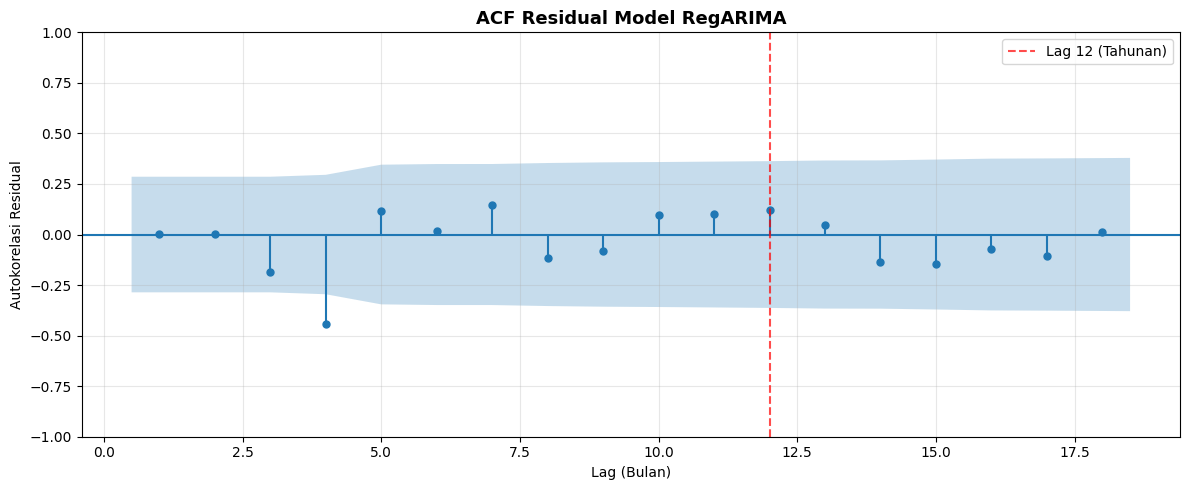

In [20]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

# Mengambil residual model RegARIMA
# Observasi pertama dikeluarkan karena inisialisasi model
residual = hasil_regarima_const.resid.iloc[1:]

# Membuat grafik ACF residual
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    residual,
    lags=18,
    alpha=0.05,
    zero=False,
    ax=ax
)

ax.set_title(
    "ACF Residual Model RegARIMA",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Lag (Bulan)")
ax.set_ylabel("Autokorelasi Residual")

ax.axvline(
    x=12,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Lag 12 (Tahunan)"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Pemodelan Awal Holt-Winters

In [22]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Menggunakan residual yang sama dengan grafik ACF
residual_bersih = hasil_regarima_const.resid.iloc[1:]

# Uji Ljung-Box pada lag 4, 6, dan 12
hasil_lb = acorr_ljungbox(
    residual_bersih,
    lags=[4, 6, 12],
    model_df=1,
    return_df=True
)

print("VALIDASI UJI LJUNG-BOX")
display(hasil_lb)

print("\nKesimpulan:")
for lag, row in hasil_lb.iterrows():
    p = row["lb_pvalue"]

    if p < 0.05:
        print(f"Lag {lag}: Masih ada indikasi autokorelasi (p={p:.4f})")
    else:
        print(f"Lag {lag}: Tidak cukup bukti autokorelasi (p={p:.4f})")

VALIDASI UJI LJUNG-BOX


,lb_stat,lb_pvalue
4,12.267537,0.006521
6,13.057939,0.022842
12,17.719879,0.088312



Kesimpulan:
Lag 4: Masih ada indikasi autokorelasi (p=0.0065)
Lag 6: Masih ada indikasi autokorelasi (p=0.0228)
Lag 12: Tidak cukup bukti autokorelasi (p=0.0883)


In [23]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Data latih dalam miliar rupiah
y_train = train["Realisasi_BPHTB"].asfreq("MS") / 1e9

# Membentuk model Holt-Winters
model_hw = ExponentialSmoothing(
    y_train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

# Melatih model
hasil_hw = model_hw.fit(optimized=True)

# Menampilkan hasil
print("HASIL MODEL HOLT-WINTERS")
print("\nParameter Model:")
for parameter, nilai in hasil_hw.params.items():
    if not isinstance(nilai, (list, tuple, np.ndarray)):
        print(f"{parameter}: {nilai}")

print("\nAIC:", hasil_hw.aic)
print("SSE:", hasil_hw.sse)

HASIL MODEL HOLT-WINTERS

Parameter Model:
smoothing_level: 1.4901161193847656e-08
smoothing_trend: 7.169935939458166e-10
smoothing_seasonal: 0.0
damping_trend: nan
initial_level: 106.23237453492447
initial_trend: 0.1985444893201
use_boxcox: False
lamda: None
remove_bias: False

AIC: 381.3145957532947
SSE: 69465.70263174092
